# Rules per FOV

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

ROOT = next(
    folder for folder in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (folder / "result_summary" / "data_helper.py").exists()
)
sys.path[:0] = [
    str(ROOT / "result_summary"),
    str(ROOT / "result_summary" / "complex_rules" / "scripts"),
    str(ROOT / "result_summary" / "differential_rules" / "scripts"),
]

import data_helper as dh
import final_figures_vis as fv
import significance_histograms_vis as sh
import vis_helper as vh

In [2]:
P_CUT = 0.05
MAX_FDR = 0.05
N_FOVS = 4
LABELS = sh.group_labels(P_CUT, MAX_FDR)

## Data

In [3]:
df_cells, df_fovs, df_biopsy = dh.load_spatial_data()
vh.set_cell_colors(df_cells)
rules = dh._read_rules(dh.RESULT_CSV_PATH, rule_max_items=2)
rules = rules[rules["Rule_Type"].eq("pairwise") & rules["FOV"].isin(df_fovs["FOV"])]

Dropped 21 FOVs: Control_S
Loaded 598093 cells; FOVs: 267, biopsies: 73, patients: 71
Read results_CN_pairwise.csv


## Rules per FOV

In [4]:
counts = pd.crosstab(rules["FOV"], sh.significance(rules, P_CUT, MAX_FDR)).reindex(columns=[0, 1, 2], fill_value=0)
counts = counts.sort_values(0, ascending=False)
spots = np.linspace(0, len(counts) - 1, N_FOVS).round().astype(int)
marked = {counts.index[spot]: f"F.{n}" for n, spot in enumerate(spots, 1)}

## Plots

saved C:\Users\Owner\Documents\script-rule-mining\result_summary\final_figures\summary_downloads\rules_per_fov.pdf


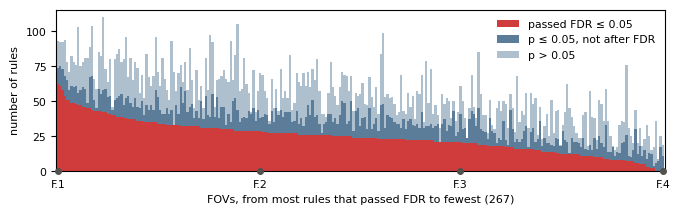

In [5]:
fv.plot_rules_per_fov(counts, marked, sh.COLORS, LABELS, save="rules_per_fov.pdf")

saved summary_downloads\rules_per_fov_examples.pdf


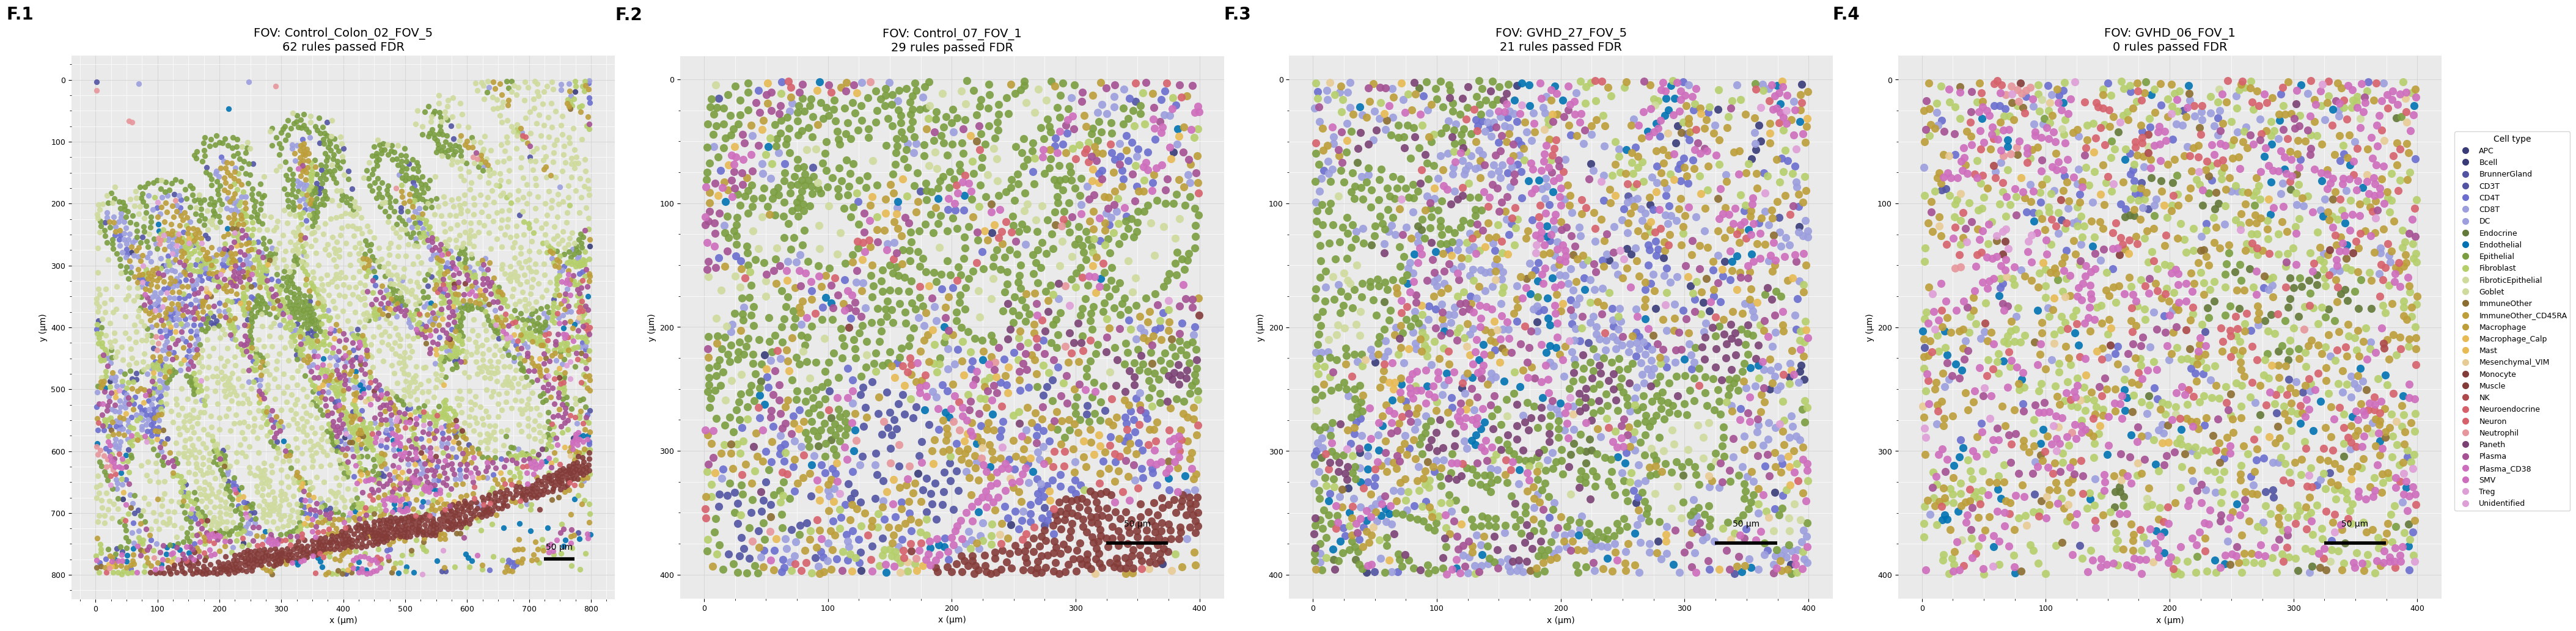

In [7]:
vh.plot_fov_panel({fov: f"{counts.loc[fov, 0]} rules passed FDR" for fov in marked},
                  df_cells, df_fovs, num_cols=N_FOVS, tags=marked, one_legend=True,
                  save="rules_per_fov_examples.pdf")